# 03 - Compare clustering settings

Compare keeping zeros with treating zeros as missing. Try k=3..8 and seeds 42, 43, 44, then fit one GMM comparison. Only training fits preprocessing; validation selects settings. Test data is not used to choose them.

In [1]:
from pathlib import Path
import json
import platform
import sys

assert platform.system() == "Linux", "Use the WSL project kernel."
assert Path(sys.prefix).name == "mlop-pj", "Select the project environment."
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if p.name == "MLOP-PJ" and (p / "README.md").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.train import run_study
config = json.loads((ROOT / "configs/study.json").read_text())
print(json.dumps(config, indent=2))


{
  "k_values": [
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "seeds": [
    42,
    43,
    44
  ],
  "zero_policies": [
    "keep_zero",
    "zero_as_missing"
  ],
  "n_init": 10,
  "min_validation_cluster_fraction": 0.02,
  "min_stability_ari": 0.8,
  "bundle_seed": 42,
  "distance_quantile": 0.95
}


## 1. Run the study

This runs 36 small K-Means fits and one GMM fit locally. Progress is printed for each K-Means run. If a cell fails, stop and keep the error output.

In [2]:
summary, selection = run_study(ROOT)
summary.round(4)


Run 1/36: keep_zero, k=3, seed=42
Run 2/36: keep_zero, k=3, seed=43
Run 3/36: keep_zero, k=3, seed=44
Run 4/36: keep_zero, k=4, seed=42
Run 5/36: keep_zero, k=4, seed=43
Run 6/36: keep_zero, k=4, seed=44
Run 7/36: keep_zero, k=5, seed=42
Run 8/36: keep_zero, k=5, seed=43
Run 9/36: keep_zero, k=5, seed=44
Run 10/36: keep_zero, k=6, seed=42
Run 11/36: keep_zero, k=6, seed=43
Run 12/36: keep_zero, k=6, seed=44
Run 13/36: keep_zero, k=7, seed=42
Run 14/36: keep_zero, k=7, seed=43
Run 15/36: keep_zero, k=7, seed=44
Run 16/36: keep_zero, k=8, seed=42
Run 17/36: keep_zero, k=8, seed=43
Run 18/36: keep_zero, k=8, seed=44
Run 19/36: zero_as_missing, k=3, seed=42
Run 20/36: zero_as_missing, k=3, seed=43
Run 21/36: zero_as_missing, k=3, seed=44
Run 22/36: zero_as_missing, k=4, seed=42
Run 23/36: zero_as_missing, k=4, seed=43
Run 24/36: zero_as_missing, k=4, seed=44
Run 25/36: zero_as_missing, k=5, seed=42
Run 26/36: zero_as_missing, k=5, seed=43
Run 27/36: zero_as_missing, k=5, seed=44
Run 28/36:

,zero_policy,k,mean_silhouette,stability_ari,min_cluster_fraction,eligible
2,keep_zero,5,0.1448,1.0000,0.0392,True
0,keep_zero,3,0.1431,1.0000,0.1860,True
3,keep_zero,6,0.1430,0.9924,0.0379,True
9,zero_as_missing,6,0.1430,0.7340,0.0428,False
8,zero_as_missing,5,0.1414,1.0000,0.0441,True
6,zero_as_missing,3,0.1409,1.0000,0.1775,True
1,keep_zero,4,0.1407,0.9942,0.1297,True
11,zero_as_missing,8,0.1406,0.6360,0.0416,False
10,zero_as_missing,7,0.1367,0.8659,0.0416,True
5,keep_zero,8,0.1367,0.7636,0.0355,False


## 2. Compare the results

Higher silhouette means better separation, not accuracy. ARI compares predictions on the same validation rows across seeds. A candidate needs ARI >=0.8 and every validation cluster >=2%, then the best mean silhouette wins.

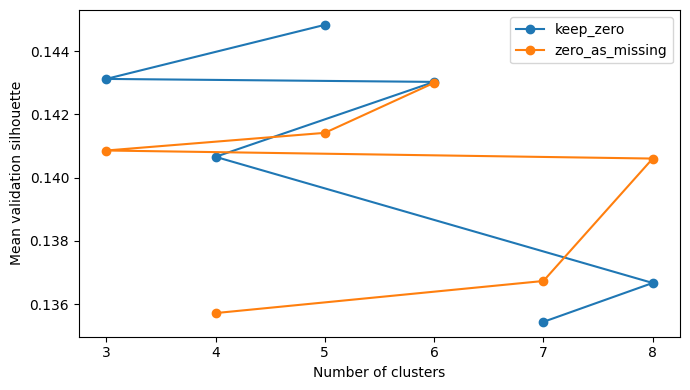

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
for policy, group in summary.groupby("zero_policy"):
    ax.plot(group["k"], group["mean_silhouette"], marker="o", label=policy)
ax.set(xlabel="Number of clusters", ylabel="Mean validation silhouette")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "reports/validation-silhouette.png", dpi=150)
plt.show()


## 3. Check the selected candidate

The zero representation choice does not prove what zero means in the source data. GMM is a comparison; K-Means remains the main model. Only continue to 04 if `ready_for_bundle` is true.

In [4]:
print(json.dumps(selection, indent=2))
print("Next:", "Notebook 04" if selection["ready_for_bundle"] else "Stop and review stability/cluster sizes")


{
  "model_type": "kmeans",
  "zero_policy": "keep_zero",
  "k": 5,
  "mean_silhouette": 0.14482709994043333,
  "stability_ari": 1.0,
  "min_cluster_fraction": 0.03916768665850673,
  "eligible": true,
  "seed": 42,
  "n_init": 10,
  "distance_quantile": 0.95,
  "ready_for_bundle": true,
  "gmm_comparison": {
    "silhouette": 0.09570735065767336,
    "davies_bouldin": 2.8294283864324576,
    "min_cluster_fraction": 0.07588739290085679,
    "cluster_counts": [
      230,
      76,
      127,
      62,
      322
    ],
    "converged": true
  },
  "raw_sha256": "c07e7751f429ebe6225a77a32e61770dbb7197fd253f667e0434424adbaf7a33",
  "prepared_report_sha256": "6f36c51741fe748574cb5c21cc220305d2c9c59f635c3f462002f9e23fdc4816",
  "study_config_sha256": "545d94ee317c2298a36c459b1cdec86b3cdf6d18da1591d4f61eaa76922eb9b5",
  "code_sha256": {
    "src/data.py": "137524721db5fed7f06174f1092ca3f4e0544877daddc342b5c9727b3b9727a4",
    "src/train.py": "96ce6842aced2a4900f71658072d5992fdaf068032c8317154

## Output

`reports/study-runs.csv`, `study-summary.csv`, `selection.json`, and `validation-silhouette.png`. Save the notebook with its output.